# Bell-Test Lab: walkthrough

This notebook calls the same Python package that runs inside the Qollab project (`bellkit`).
Every number below is computed when the notebook is executed. For the same request and seed, the
app gives the same numbers on Qollab's built-in simulator and in the local harness.

Run it from the repository root (the data paths are relative to it, as on Qollab). Simulated
counts and asymptotic formulas only: no quantum hardware and no security proof.

In [1]:
import json
import sys

sys.path.insert(0, ".")
from qiskit.providers.basic_provider import BasicSimulator

from bellkit import app, bounds, config, models, rosenfeld
from bellkit.channels import PauliChannel
from bellkit.circuits import Experiment, build_plan, make_units, qubit_labels

cfg = config.load()
settings = config.settings(cfg)

## 1. One Bell run
Six settings (Alice $0^\circ$, $90^\circ$, $\pm 45^\circ$; Bob $0^\circ$, $90^\circ$) in one job, with 5% depolarizing noise on Bob's link, on Qiskit's BasicSimulator.

In [2]:
request = {"module": "bell", "channel": {"kind": "depolarizing", "strength": 0.05}}
rep = json.loads(app.run_json(BasicSimulator(), json.dumps(request)))
a = rep["analysis"]
print(f"backend {rep['backend']['name']}, {rep['shots']} shots per setting, layout {rep['layout']}")
level = 100 * (1 - a["delta"] / 2)  # each interval at 97.5 %, so each claim holds at 95 %
print(f"S   = {a['S']['point']:.3f}   {level:.1f}% interval [{a['S']['low']:.3f}, {a['S']['high']:.3f}]")
print(f"exact prediction S = {rep['prediction']['S_fixed']:.3f}")
print(f"Q_Z = {a['Q_Z']['point']:.2%}   Q_X = {a['Q_X']['point']:.2%}")

backend basic_simulator, 10000 shots per setting, layout multi_circuit
S   = 2.708   97.5% interval [2.649, 2.767]
exact prediction S = 2.687
Q_Z = 2.36%   Q_X = 2.47%


## 2. The certificate ladder
Each claim at the point estimate and at the conservative end ($S$ at its lower end, error rates at their upper ends).

In [3]:
RUNGS = [
    ("Bell violation", "bell_violation"),
    ("Entanglement witness (fidelity >=)", "witness_fidelity_low"),
    ("BBM92 key rate (bit/round)", "rate_bbm92"),
    ("Self-test extractability (Kaniewski)", "kaniewski_extractability"),
    ("DI randomness H_min (Pironio)", "min_entropy_pironio"),
    ("DI key rate (Acin 2007)", "rate_di_acin"),
]


def show(v):
    return f"{v:.3f}" if isinstance(v, float) else ("none" if v is None else str(v))


for label, key in RUNGS:
    p, c = show(a["ladder_point"][key]), show(a["ladder_conservative"][key])
    print(f"{label:38s} point {p:>6}   conservative {c:>6}")

Bell violation                         point   True   conservative   True
Entanglement witness (fidelity >=)     point  0.952   conservative  0.931
BBM92 key rate (bit/round)             point  0.672   conservative  0.633
Self-test extractability (Kaniewski)   point  0.917   conservative  0.876
DI randomness H_min (Pironio)          point  0.506   conservative  0.419
DI key rate (Acin 2007)                point  0.580   conservative  0.469


## 3. One of the circuits
The Pauli channel uses two ancilla qubits. Qiskit's own drawing:

In [4]:
exp = Experiment("bell", PauliChannel.from_kind("depolarizing", 0.05))
units = make_units(exp, settings, None)
plan = build_plan(units[:1], "multi_circuit")
print(units[0].setting["id"], qubit_labels(units[0]))
print(plan.circuits[0].draw(output="text", fold=-1))

key_z ['Alice', 'Bob', 'noise x', 'noise z']
          ┌───┐                   ┌───────┐   ┌─┐            
q_0: ─────┤ H ├───────────■───────┤ Ry(0) ├───┤M├────────────
          └───┘         ┌─┴─┐     └─┬───┬─┘   └╥┘┌───────┐┌─┐
q_1: ───────────────────┤ X ├───────┤ X ├───■──╫─┤ Ry(0) ├┤M├
     ┌─────────────┐    └───┘       └─┬─┘   │  ║ └───────┘└╥┘
q_2: ┤ Ry(0.31756) ├──────■───────────■─────┼──╫───────────╫─
     ├─────────────┤┌─────┴──────┐          │  ║           ║ 
q_3: ┤ Ry(0.22694) ├┤ Ry(1.3439) ├──────────■──╫───────────╫─
     └─────────────┘└────────────┘             ║           ║ 
c: 2/══════════════════════════════════════════╩═══════════╩═
                                               0           1 


## 4. Thresholds, computed from the formulas

In [5]:
th = bounds.thresholds()
for name, v in th.items():
    if isinstance(v, dict):
        print(f"{name:10s}", {k: round(x, 4) for k, x in v.items()})
    else:
        print(f"{name:10s}", round(v, 4))

chsh       {'S': 2.0, 'Q_werner': 0.1464, 'v_werner': 0.7071}
kaniewski  {'S': 2.1058, 'Q_werner': 0.1277, 'v_werner': 0.7445}
bbm92      {'S_werner': 2.206, 'Q': 0.11, 'v_werner': 0.7799}
acin       {'S_werner': 2.424, 'Q_werner': 0.0715, 'v_werner': 0.857}
witness    {'v_werner': 0.5}
tsirelson  2.8284


## 5. Noise sweep
$S$ and the device-independent key rate for each named channel (exact model).

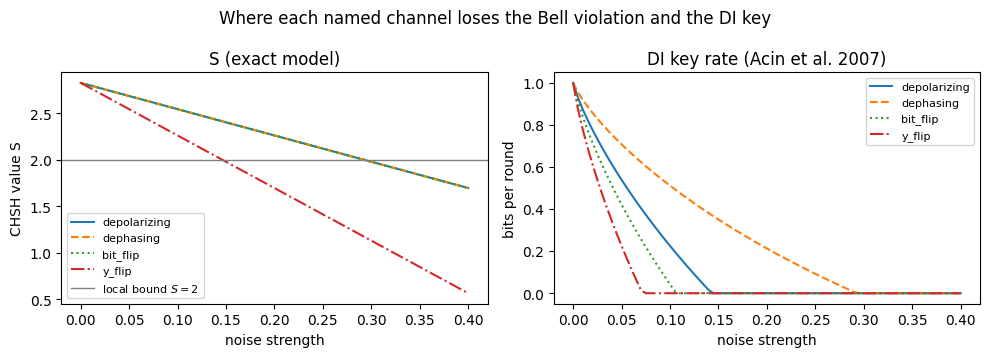

In [6]:
import matplotlib.pyplot as plt

qs = [i / 200 for i in range(81)]
kinds = (("depolarizing", "-"), ("dephasing", "--"), ("bit_flip", ":"), ("y_flip", "-."))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for kind, ls in kinds:
    preds = [models.predict(PauliChannel.from_kind(kind, q), settings) for q in qs]
    axes[0].plot(qs, [p["S_fixed"] for p in preds], ls, label=kind)
    rates = [max(0.0, bounds.di_rate_acin(p["S_fixed"], p["Q_Z"]) or 0.0) for p in preds]
    axes[1].plot(qs, rates, ls, label=kind)
axes[0].axhline(2, color="grey", lw=1, label=r"local bound $S = 2$")
axes[0].set(xlabel="noise strength", ylabel="CHSH value S", title="S (exact model)")
axes[1].set(xlabel="noise strength", ylabel="bits per round", title="DI key rate (Acin et al. 2007)")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.suptitle("Where each named channel loses the Bell violation and the DI key")
plt.tight_layout()
plt.show()

The same information as text: the noise strength at which each channel reaches $S = 2$ and at which the DI key rate reaches zero.

In [7]:
def crossing(kind, f):
    lo, hi = 0.0, 1.0
    if f(PauliChannel.from_kind(kind, hi)) > 0:
        return None
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if f(PauliChannel.from_kind(kind, mid)) > 0 else (lo, mid)
    return lo


def margin_s(ch):
    return models.predict(ch, settings)["S_fixed"] - 2


def margin_di(ch):
    p = models.predict(ch, settings)
    return bounds.di_rate_acin(p["S_fixed"], p["Q_Z"]) or -1.0


print(f"{'channel':14s} {'S = 2 at':>10s} {'DI key = 0 at':>14s}")
for kind, _ in kinds:
    print(f"{kind:14s} {crossing(kind, margin_s):10.4f} {crossing(kind, margin_di):14.4f}")

channel          S = 2 at  DI key = 0 at
depolarizing       0.2929         0.1430
dephasing          0.2929         0.2929
bit_flip           0.2929         0.1064
y_flip             0.1464         0.0715


## 6. Entanglement swapping
$S$ against the number of links for 5% depolarizing noise per link.

In [8]:
channel = PauliChannel.from_kind("depolarizing", 0.05)
for n in range(1, 5):
    p = models.predict(channel, settings, hops=n)
    print(f"{n} link(s): S = {p['S_fixed']:.3f}   Q_Z = {p['Q_Z']:.2%}")

1 link(s): S = 2.687   Q_Z = 2.50%
2 link(s): S = 2.553   Q_Z = 4.88%
3 link(s): S = 2.425   Q_Z = 7.13%
4 link(s): S = 2.304   Q_Z = 9.27%


## 7. Real data: the Munich 2017 Bell test
The first 5,000 events per heralded state, as in the paper (Rosenfeld et al. 2017, $S = 2.221 \pm 0.033$ for the April run).

In [9]:
for run in rosenfeld.RUNS:
    r = rosenfeld.analyse_run(run, 5000, 0.05, 10)
    print(
        f"{r['label']}: S = {r['pooled']['S']:.4f} ± {r['pooled']['se']:.4f}, "
        f"Hoeffding lower end {r['S_low']:.4f}"
    )

15 April 2016 run (main-text S): S = 2.2213 ± 0.0332, Hoeffding lower end 2.1126
14 June 2016 public run: S = 2.0957 ± 0.0340, Hoeffding lower end 1.9870


## 8. The packed layout used for IonQ
On Qollab, the IonQ simulator accepts one circuit per job, so the settings share one circuit, with a canary register that checks the bit order.

In [10]:
packed = build_plan(units, "packed_single_circuit")
qc = packed.circuits[0]
print(qc.num_qubits, "qubits,", len(qc.cregs), "classical registers (canary first)")
print("clbit offset of each setting:", [offset for _, _, offset in packed.placements])

25 qubits, 7 classical registers (canary first)
clbit offset of each setting: [1, 3, 5, 7, 9, 11]
